In [7]:
import os
import random
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
os.environ["PYTHONHASHSEED"] = str(SEMILLA)

RUTA = "../../s23-feature-engineering-clinico/tu-entrega/features.csv"
df = pd.read_csv(RUTA, parse_dates=["fecha_indice"])
df = df.sort_values("fecha_indice").reset_index(drop=True)

corte = df["fecha_indice"].quantile(0.8)
entreno = df[df["fecha_indice"] < corte]
prueba = df[df["fecha_indice"] >= corte]

NO_FEATURES = ["person_id", "fecha_indice", "muerte_90d"]
X_train = entreno.drop(columns=NO_FEATURES)
y_train = entreno["muerte_90d"]
X_test = prueba.drop(columns=NO_FEATURES)
y_test = prueba["muerte_90d"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

print("Corte temporal:", corte.date())
print(f"Entrenamiento: {X_train.shape}, muertes {y_train.sum()} ({y_train.mean():.2%})")
print(f"Prueba:        {X_test.shape}, muertes {y_test.sum()} ({y_test.mean():.2%})")

Corte temporal: 2023-01-27
Entrenamiento: (4296, 34), muertes 306 (7.12%)
Prueba:        (1076, 34), muertes 63 (5.86%)


In [8]:
np.random.seed(42)
print(np.random.rand(3))
np.random.seed(42)
print(np.random.rand(3))

[0.37454012 0.95071431 0.73199394]
[0.37454012 0.95071431 0.73199394]


In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

def con_escala(modelo):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                         StandardScaler(),
                         modelo)

def sin_escala(modelo):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                         modelo)

catalogo = {
    "DummyClassifier": sin_escala(DummyClassifier(strategy="prior")),
    "Regresión logística": con_escala(LogisticRegression(C=1.0, max_iter=2000)),
    "k-NN": con_escala(KNeighborsClassifier(n_neighbors=25)),
    "SVM (RBF)": con_escala(SVC(kernel="rbf", random_state=SEMILLA)),
    "Random Forest": sin_escala(RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEMILLA)),
    "XGBoost": sin_escala(XGBClassifier(n_estimators=300, n_jobs=-1, random_state=SEMILLA)),
    "LightGBM": sin_escala(LGBMClassifier(n_estimators=300, random_state=SEMILLA, verbose=-1)),
}

filas = []
for nombre, pipe in catalogo.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv,
                         scoring=["roc_auc", "average_precision"])
    filas.append({
        "modelo": nombre,
        "AUROC": res["test_roc_auc"].mean(),
        "AUROC_de": res["test_roc_auc"].std(),
        "AUPRC": res["test_average_precision"].mean(),
        "AUPRC_de": res["test_average_precision"].std(),
        "tiempo_s": res["fit_time"].sum(),
    })
    print(f"{nombre:20s} listo")

catalogo_res = pd.DataFrame(filas).sort_values("AUROC", ascending=False)
catalogo_res.round(3)

DummyClassifier      listo
Regresión logística  listo
k-NN                 listo
SVM (RBF)            listo
Random Forest        listo
XGBoost              listo
LightGBM             listo


,modelo,AUROC,AUROC_de,AUPRC,AUPRC_de,tiempo_s
4,Random Forest,0.832,0.022,0.425,0.029,3.020
6,LightGBM,0.811,0.018,0.380,0.027,1.059
5,XGBoost,0.802,0.012,0.368,0.028,1.977
1,Regresión logística,0.791,0.019,0.231,0.017,0.104
2,k-NN,0.776,0.022,0.244,0.022,0.085
3,SVM (RBF),0.723,0.020,0.293,0.023,0.500
0,DummyClassifier,0.500,0.000,0.071,0.000,0.041


## Actividad 2. 

**Random Forest (1.º, AUROC 0.832, AUPRC 0.425).** Supone que el riesgo se arma con umbrales e interacciones , sin pedir que la relación sea lineal. Además promedia 500 árboles hechos con submuestras distintas, y eso reduce la varianza. Con solo 306 eventos, ese promedio lo hace robusto, y por eso ganó sin ajustar nada.

**LightGBM (2.º, 0.811) y XGBoost (3.º, 0.802).** También capturan umbrales e interacciones, pero construyen los árboles en secuencia, cada uno corrigiendo los errores del anterior. Con los valores por defecto (300 árboles, sin early stopping, `num_leaves=31` en LightGBM) son demasiado flexibles para unos miles de filas y tienden a sobreajustar. Por eso quedan detrás del bosque. Se espera que suban al ajustarlos (actividades 3 a 6).

**Regresión logística (4.º, 0.791 pero AUPRC 0.231).** Supone que cada variable suma riesgo de forma lineal y monótona en la escala logit. El AUROC queda cerca porque muchas de mis variables ya son riesgos monótonos (edad, insuficiencia cardiaca, albúmina baja). El AUPRC tan bajo indica que no logra concentrar las muertes en el extremo de mayor riesgo: le faltan las interacciones y los umbrales que sí ven los árboles.

**SVM con kernel RBF (el peor, después del Dummy; 0.723).** Supone que pacientes cercanos en distancia euclidiana, con todas las variables escaladas, tienen el mismo desenlace. Con 34 variables más los indicadores, muchas binarias o poco informativas, todas pesan igual en la distancia y el ruido tapa la señal. Además, con 7 % de eventos el margen lo dominan los sobrevivientes. Fue rápido (0.5 s), pero no aportó nada sobre modelos más simples. k-NN (0.776) sufre por el mismo supuesto de distancia.

In [10]:
resultados_nl = []
for hojas, profundidad in [(31, -1), (7, 3)]:
    pipe = sin_escala(LGBMClassifier(n_estimators=300, num_leaves=hojas, max_depth=profundidad,
                                     random_state=SEMILLA, verbose=-1))
    res = cross_validate(pipe, X_train, y_train, cv=cv,
                         scoring=["roc_auc", "average_precision"],
                         return_train_score=True)
    resultados_nl.append({
        "num_leaves": hojas,
        "max_depth": profundidad,
        "AUROC_entreno": res["train_roc_auc"].mean(),
        "AUROC_cv": res["test_roc_auc"].mean(),
        "AUROC_de": res["test_roc_auc"].std(),
        "AUPRC_cv": res["test_average_precision"].mean(),
        "AUPRC_de": res["test_average_precision"].std(),
    })
pd.DataFrame(resultados_nl).round(3)

,num_leaves,max_depth,AUROC_entreno,AUROC_cv,AUROC_de,AUPRC_cv,AUPRC_de
0,31,-1,1.000,0.811,0.018,0.380,0.027
1,7,3,0.992,0.807,0.011,0.356,0.036


## Actividad 3. LightGBM y num_leaves

| num_leaves | max_depth | AUROC entreno | AUROC CV (DE) | AUPRC CV (DE) |
|---|---|---|---|---|
| 31 (defecto) | sin límite | 1.000 | 0.811 (0.018) | 0.380 (0.027) |
| 7 | 3 | 0.992 | 0.807 (0.011) | 0.356 (0.036) |

Con el valor por defecto el modelo memoriza el entrenamiento (AUROC 1.000) y cae a 0.811 en validación, que es sobreajuste. Reducir a 7 hojas, con max_depth=3, casi no cerró la brecha (0.992 contra 0.807). En esta cohorte, el sobreajuste viene al parecer de acumular 300 árboles sin control: el número de árboles es lo que hay que frenar.

/home/alecedillo/s10-sql-fundamentals/venv/lib64/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Ajuste: 3436 | Validación: 860 | Prueba (sin tocar): 1076
Se detuvo en 124 árboles; AUROC de validación = 0.836


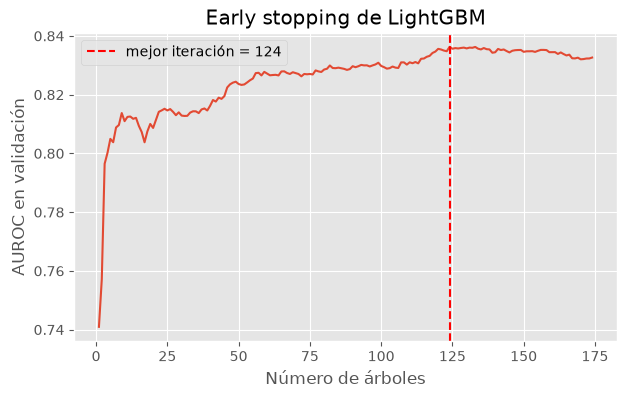

In [11]:
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

X_ajuste, X_val, y_ajuste, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEMILLA)

imputador = SimpleImputer(strategy="median", add_indicator=True)
X_ajuste_imp = imputador.fit_transform(X_ajuste)
X_val_imp = imputador.transform(X_val)

historia = {}
modelo_es = LGBMClassifier(n_estimators=2000, learning_rate=0.05, num_leaves=7, max_depth=3,
                           random_state=SEMILLA, verbose=-1)
modelo_es.fit(X_ajuste_imp, y_ajuste,
              eval_set=[(X_val_imp, y_val)],
              eval_metric="auc",
              callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False),
                         lgb.record_evaluation(historia)])

mejor = modelo_es.best_iteration_
auc_val = roc_auc_score(y_val, modelo_es.predict_proba(X_val_imp)[:, 1])
print(f"Ajuste: {X_ajuste.shape[0]} | Validación: {X_val.shape[0]} | Prueba (sin tocar): {X_test.shape[0]}")
print(f"Se detuvo en {mejor} árboles; AUROC de validación = {auc_val:.3f}")

curva = historia["valid_0"]["auc"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(curva) + 1), curva)
ax.axvline(mejor, color="red", linestyle="--", label=f"mejor iteración = {mejor}")
ax.set_xlabel("Número de árboles")
ax.set_ylabel("AUROC en validación")
ax.set_title("Early stopping de LightGBM")
ax.legend()
fig.savefig("curva_early_stopping.png", dpi=150, bbox_inches="tight")
plt.show()

## Actividad 4. Early stopping con tres conjuntos

Tres conjuntos: ajuste (3,436), validación (860) y prueba (1,076). LightGBM con learning_rate=0.05, num_leaves=7, max_depth=3, techo de 2000 árboles y paciencia de 50.

- Se detuvo en **124 árboles**, con AUROC de validación de **0.836**.
- Curva: `curva_early_stopping.png`. Sube rápido hasta unos 25 árboles, llega a una meseta hacia los 60 y deja de mejorar después de 124, así que los 300 árboles por defecto de la actividad 3 eran más de lo necesario.

El early stopping elige un hiperparámetro (el número de árboles) mirando la métrica del conjunto que recibe. 

Tiempo: 0.5 min | completos: 72 | podados: 28
Mejor AUROC CV: 0.842 (trial 97)
Árboles promedio del mejor: 125
Mejores hiperparámetros: {'max_depth': 6, 'learning_rate': 0.016707241408389428, 'num_leaves': 18, 'min_child_samples': 19, 'subsample': 0.7928741310372845, 'colsample_bytree': 0.9098585036344119, 'reg_lambda': 6.9832771926424035}


/tmp/ipykernel_637942/848170258.py:57: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(estudio)


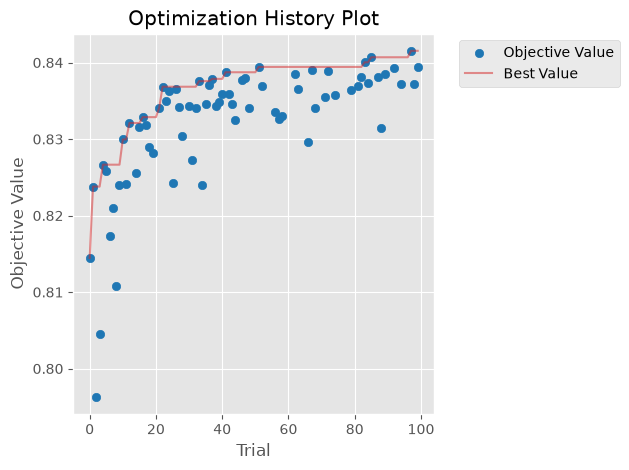

/tmp/ipykernel_637942/848170258.py:60: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_param_importances(estudio)


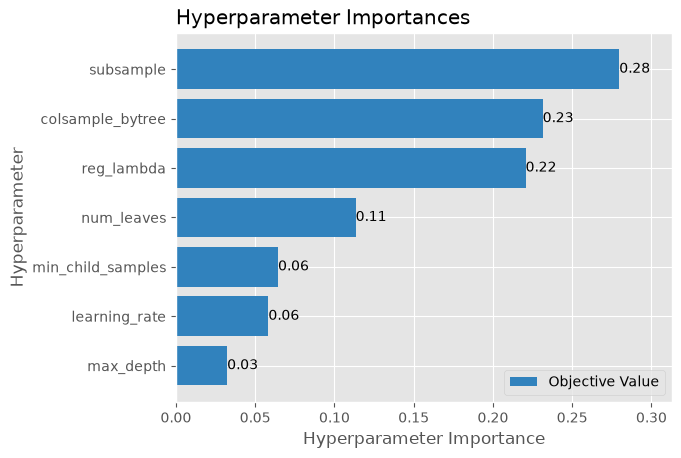

In [12]:
import optuna
from sklearn.model_selection import train_test_split
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objetivo(trial):
    max_depth = trial.suggest_int("max_depth", 2, 6)
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": max_depth,
        "num_leaves": min(trial.suggest_int("num_leaves", 4, 31), 2 ** max_depth - 1),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 100),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }
    aucs, arboles = [], []
    for paso, (i_aj, i_va) in enumerate(cv.split(X_train, y_train)):
        X_aj, X_va = X_train.iloc[i_aj], X_train.iloc[i_va]
        y_aj, y_va = y_train.iloc[i_aj], y_train.iloc[i_va]
        X_aj, X_es, y_aj, y_es = train_test_split(
            X_aj, y_aj, test_size=0.15, stratify=y_aj, random_state=SEMILLA)
        imp = SimpleImputer(strategy="median", add_indicator=True)
        X_aj = imp.fit_transform(X_aj)
        X_es = imp.transform(X_es)
        X_va = imp.transform(X_va)
        m = LGBMClassifier(n_estimators=2000, random_state=SEMILLA, verbose=-1, **params)
        m.fit(X_aj, y_aj, eval_X=X_es, eval_y=y_es, eval_metric="auc",
              callbacks=[lgb.early_stopping(50, verbose=False)])
        aucs.append(roc_auc_score(y_va, m.predict_proba(X_va)[:, 1]))
        arboles.append(m.best_iteration_)
        trial.report(np.mean(aucs), paso)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("n_arboles", int(np.mean(arboles)))
    return np.mean(aucs)

estudio = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEMILLA),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=1),
    study_name="lgbm_auroc",
)
t0 = time.time()
estudio.optimize(objetivo, n_trials=100)
minutos = (time.time() - t0) / 60

podados = [t for t in estudio.trials if t.state == optuna.trial.TrialState.PRUNED]
completos = [t for t in estudio.trials if t.state == optuna.trial.TrialState.COMPLETE]
print(f"Tiempo: {minutos:.1f} min | completos: {len(completos)} | podados: {len(podados)}")
print(f"Mejor AUROC CV: {estudio.best_value:.3f} (trial {estudio.best_trial.number})")
print("Árboles promedio del mejor:", estudio.best_trial.user_attrs["n_arboles"])
print("Mejores hiperparámetros:", estudio.best_params)

ax = plot_optimization_history(estudio)
plt.savefig("optuna_historia.png", dpi=150, bbox_inches="tight")
plt.show()
ax = plot_param_importances(estudio)
plt.savefig("optuna_importancia.png", dpi=150, bbox_inches="tight")
plt.show()

## Actividad 6. Optimización con Optuna y pruning

- 100 trials con TPESampler(seed=42) y MedianPruner (10 trials de arranque; poda desde el 2.º pliegue). Early stopping dentro de cada pliegue.
- Tiempo: 0.5 min. Completos: **72**. Podados: **28**.
- **Mejor AUROC en CV: 0.842** (trial 97), con unos 125 árboles en promedio.
- Mejores hiperparámetros: max_depth = 6, learning_rate = 0.0168, num_leaves = 18, min_child_samples = 19, subsample = 0.79, colsample_bytree = 0.91, reg_lambda = 6.98.
- Gráficas: `optuna_historia.png` y `optuna_importancia.png`.

**Lectura.** La historia muestra que casi toda la mejora ocurre en los primeros 20 a 40 trials (meseta alrededor de 0.84). En la importancia, tres parámetros explican el 73 % de la variación del AUROC: subsample (0.28), colsample_bytree (0.23) y reg_lambda (0.22). learning_rate (0.06) y max_depth (0.03) casi no importaron dentro de sus rangos, probablemente porque el early stopping compensa la tasa de aprendizaje con más o menos árboles. 

**Advertencia.** El 0.842 es el mejor de 100 intentos evaluados sobre los mismos pliegues, si está sesgado hacia arriba, entonces la estimación honesta del desempeño esperado viene del nested CV (actividad 8).

## Actividad 7 

In [13]:
import duckdb

BASE = "/home/alecedillo/s12-omop-cdm-introduccion/omop_20k.duckdb"
con = duckdb.connect(BASE, read_only=True)

consulta = """
WITH base AS (
  SELECT co.subject_id AS person_id,
         co.cohort_start_date AS fecha_indice,
         op.observation_period_end_date AS obs_fin,
         d.death_date
  FROM results.cohort co
  JOIN observation_period op
    ON op.person_id = co.subject_id
   AND co.cohort_start_date BETWEEN op.observation_period_start_date
                                AND op.observation_period_end_date
  LEFT JOIN death d ON d.person_id = co.subject_id
  WHERE co.cohort_definition_id = 1701
),
fin_datos AS (
  SELECT MAX(observation_period_end_date) AS ultima_fecha FROM observation_period
)
SELECT
  CASE
    WHEN death_date <= fecha_indice THEN '0. muerte en o antes del egreso (excluido)'
    WHEN death_date <= fecha_indice + INTERVAL 90 DAY THEN '1. completo: murió en [1, 90]'
    WHEN obs_fin >= fecha_indice + INTERVAL 90 DAY THEN '2. completo: vivo y observado 90 días'
    WHEN obs_fin >= f.ultima_fecha - INTERVAL 7 DAY THEN '3. censurado: se acabó el periodo de datos'
    ELSE '4. censurado: perdido de seguimiento'
  END AS situacion,
  COUNT(*) AS n,
  ROUND(MEDIAN(DATEDIFF('day', fecha_indice, obs_fin)), 0) AS mediana_dias_observado
FROM base CROSS JOIN fin_datos f
GROUP BY situacion
ORDER BY situacion
"""
censura = con.execute(consulta).df()
con.close()
censura

,situacion,n,mediana_dias_observado
0,0. muerte en o antes del egreso (excluido),370,11.0
1,"1. completo: murió en [1, 90]",369,23.0
2,2. completo: vivo y observado 90 días,5003,1477.0
3,3. censurado: se acabó el periodo de datos,6,4.0
4,4. censurado: perdido de seguimiento,137,21.0


### Decisión sobre la censura

De las 5,885 personas de la cohorte 1701, 370 murieron en o antes del egreso y se excluyen por definición. Quedan 5,515 en riesgo, que se dividen así:

| Situación | n | Mediana de días observado |
|---|---|---|
| Completo: murió en [1, 90] | 369 | 23 |
| Completo: vivo y observado ≥ 90 días | 5,003 | 1,477 |
| Censurado: terminó la base de datos | 6 | 4 |
| Censurado: perdido de seguimiento | 137 | 21 |

**Decisión declarada:** los modelos de la Parte A y de Optuna usan solo los **5,372 casos completos** y excluyen a los **143 censurados (2.6 %)**- 

**Riesgos de esta decisión:**
- La censura casi nunca es aleatoria. Los 137 perdidos de seguimiento salieron de la base a una mediana de 21 días, y en la vida real eso puede significar traslado a otra institución, cuidados paliativos o muerte no registrada. Si varios de ellos murieron, la prevalencia real es mayor que el 6.9 % observado y el modelo subestima el riesgo absoluto.
- Al excluirlos, la discriminación (AUROC) casi no cambia.

**Por qué es aceptable aquí:** los censurados son pocos (2.6 %) y el objetivo del laboratorio es comparar modelos con el mismo conjunto de datos. 



## Actividad 8: CV simple vs CV anidada

In [14]:
def hacer_objetivo(X, y, cv_int):
    def objetivo_int(trial):
        max_depth = trial.suggest_int("max_depth", 2, 6)
        params = {
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            "max_depth": max_depth,
            "num_leaves": min(trial.suggest_int("num_leaves", 4, 31), 2 ** max_depth - 1),
            "min_child_samples": trial.suggest_int("min_child_samples", 10, 100),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "subsample_freq": 1,
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        }
        aucs = []
        for paso, (i_aj, i_va) in enumerate(cv_int.split(X, y)):
            X_aj, X_va = X.iloc[i_aj], X.iloc[i_va]
            y_aj, y_va = y.iloc[i_aj], y.iloc[i_va]
            X_aj, X_es, y_aj, y_es = train_test_split(
                X_aj, y_aj, test_size=0.15, stratify=y_aj, random_state=SEMILLA)
            imp = SimpleImputer(strategy="median", add_indicator=True)
            X_aj = imp.fit_transform(X_aj)
            X_es = imp.transform(X_es)
            X_va = imp.transform(X_va)
            m = LGBMClassifier(n_estimators=2000, random_state=SEMILLA, verbose=-1, **params)
            m.fit(X_aj, y_aj, eval_X=X_es, eval_y=y_es, eval_metric="auc",
                  callbacks=[lgb.early_stopping(50, verbose=False)])
            aucs.append(roc_auc_score(y_va, m.predict_proba(X_va)[:, 1]))
            trial.report(np.mean(aucs), paso)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return np.mean(aucs)
    return objetivo_int

def entrenar_final(params, X, y):
    params = dict(params)
    params["num_leaves"] = min(params["num_leaves"], 2 ** params["max_depth"] - 1)
    X_aj, X_es, y_aj, y_es = train_test_split(
        X, y, test_size=0.15, stratify=y, random_state=SEMILLA)
    imp = SimpleImputer(strategy="median", add_indicator=True)
    X_aj = imp.fit_transform(X_aj)
    X_es = imp.transform(X_es)
    m = LGBMClassifier(n_estimators=2000, subsample_freq=1, random_state=SEMILLA,
                       verbose=-1, **params)
    m.fit(X_aj, y_aj, eval_X=X_es, eval_y=y_es, eval_metric="auc",
          callbacks=[lgb.early_stopping(50, verbose=False)])
    return imp, m

N_TRIALS_INT = 30
cv_ext = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
cv_int = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)

externos = []
t0 = time.time()
for k, (i_tr, i_va) in enumerate(cv_ext.split(X_train, y_train), start=1):
    X_tr, X_va = X_train.iloc[i_tr], X_train.iloc[i_va]
    y_tr, y_va = y_train.iloc[i_tr], y_train.iloc[i_va]
    est_int = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEMILLA),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1),
    )
    est_int.optimize(hacer_objetivo(X_tr, y_tr, cv_int), n_trials=N_TRIALS_INT)
    imp, m = entrenar_final(est_int.best_params, X_tr, y_tr)
    auc_ext = roc_auc_score(y_va, m.predict_proba(imp.transform(X_va))[:, 1])
    externos.append({"pliegue": k, "auc_interno": est_int.best_value,
                     "auc_externo": auc_ext, "arboles": m.best_iteration_,
                     "max_depth": est_int.best_params["max_depth"],
                     "learning_rate": est_int.best_params["learning_rate"]})
    print(f"Pliegue {k}: interno {est_int.best_value:.3f} | externo {auc_ext:.3f}")

anidada = pd.DataFrame(externos)
print(f"\nTiempo: {(time.time() - t0) / 60:.1f} min")
print(f"CV simple (mejor de 100 trials): {estudio.best_value:.3f}")
print(f"CV anidada (5 pliegues externos): {anidada['auc_externo'].mean():.3f} "
      f"± {anidada['auc_externo'].std():.3f}")
print(f"Optimismo estimado: {estudio.best_value - anidada['auc_externo'].mean():+.3f}")
anidada.round(3)

Pliegue 1: interno 0.837 | externo 0.819
Pliegue 2: interno 0.811 | externo 0.854
Pliegue 3: interno 0.827 | externo 0.824
Pliegue 4: interno 0.833 | externo 0.822
Pliegue 5: interno 0.833 | externo 0.813

Tiempo: 0.5 min
CV simple (mejor de 100 trials): 0.842
CV anidada (5 pliegues externos): 0.826 ± 0.016
Optimismo estimado: +0.015


,pliegue,auc_interno,auc_externo,arboles,max_depth,learning_rate
0,1,0.837,0.819,50,6,0.030
1,2,0.811,0.854,28,4,0.062
2,3,0.827,0.824,53,6,0.035
3,4,0.833,0.822,110,5,0.032
4,5,0.833,0.813,55,6,0.018


### Conclusión de la actividad 8

| Estimación | AUROC |
|---|---|
| CV simple (mejor de 100 trials de Optuna) | 0.842 |
| CV anidada (5 pliegues externos, 30 trials internos cada uno) | **0.826 ± 0.016** |
| Optimismo estimado | +0.015 |

**Interpretación:** el 0.842 es el máximo de 100 intentos sobre los mismos pliegues La CV anidada evalúa cada pliegue con hiperparámetros que se eligieron sin verlo y estima de forma honesta el rendimiento del procedimiento completo **0.826**. 

**Estabilidad:** en 4 de 5 pliegues Optuna eligió árboles profundos (`max_depth` de 4 a 6) y un `learning_rate` bajo (0.018 a 0.035). El número de árboles varió de 28 a 110. Las combinaciones cambian entre pliegues, pero todas rinden parecido.

**Pliegue 2:** el AUROC interno fue el más bajo (0.811) y el externo el más alto (0.854). Esa diferencia entre pliegues (DE 0.016) es del mismo tamaño que el optimismo.

**Implicación para la comparación:** el LightGBM ajustado (0.826 anidado) **no supera** con claridad al Random Forest sin ajustar de la Parte A (0.832 ± 0.022). La optimización de hiperparámetros dio una ganancia real pequeña.

## Actividad 9: Intervalos de confianza

In [16]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import average_precision_score

mejores = dict(estudio.best_params)
mejores["num_leaves"] = min(mejores["num_leaves"], 2 ** mejores["max_depth"] - 1)
n_arboles = estudio.best_trial.user_attrs["n_arboles"]
catalogo["LightGBM (ajustado)"] = sin_escala(LGBMClassifier(
    n_estimators=n_arboles, subsample_freq=1, random_state=SEMILLA, verbose=-1, **mejores))

def ic_bootstrap(y, p, metrica, n_boot=1000, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    y, p = np.asarray(y), np.asarray(p)
    valores = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        valores.append(metrica(y[idx], p[idx]))
    return np.percentile(valores, [2.5, 97.5])

oof = {}
filas_ic = []
for nombre, pipe in catalogo.items():
    metodo = "decision_function" if nombre.startswith("SVM") else "predict_proba"
    pred = cross_val_predict(pipe, X_train, y_train, cv=cv, method=metodo)
    p = pred if metodo == "decision_function" else pred[:, 1]
    oof[nombre] = p
    auc_lo, auc_hi = ic_bootstrap(y_train, p, roc_auc_score)
    ap_lo, ap_hi = ic_bootstrap(y_train, p, average_precision_score)
    filas_ic.append({
        "modelo": nombre,
        "AUROC": roc_auc_score(y_train, p), "AUROC_IC95": f"{auc_lo:.3f}–{auc_hi:.3f}",
        "AUPRC": average_precision_score(y_train, p), "AUPRC_IC95": f"{ap_lo:.3f}–{ap_hi:.3f}",
    })
    print(f"{nombre:22s} listo")

tabla_ic = pd.DataFrame(filas_ic).sort_values("AUROC", ascending=False)
tabla_ic.round(3)

DummyClassifier        listo
Regresión logística    listo
k-NN                   listo
SVM (RBF)              listo
Random Forest          listo
XGBoost                listo
LightGBM               listo
LightGBM (ajustado)    listo


,modelo,AUROC,AUROC_IC95,AUPRC,AUPRC_IC95
7,LightGBM (ajustado),0.839,0.811–0.867,0.442,0.386–0.500
4,Random Forest,0.831,0.803–0.857,0.414,0.357–0.474
6,LightGBM,0.810,0.781–0.836,0.370,0.316–0.431
5,XGBoost,0.801,0.773–0.829,0.363,0.311–0.418
1,Regresión logística,0.791,0.762–0.818,0.217,0.184–0.259
2,k-NN,0.776,0.747–0.805,0.233,0.196–0.281
3,SVM (RBF),0.723,0.688–0.758,0.280,0.235–0.343
0,DummyClassifier,0.499,0.476–0.520,0.071,0.063–0.079


### Interpretación de la actividad 9

| Modelo | AUROC (IC 95 %) | AUPRC (IC 95 %) |
|---|---|---|
| LightGBM (ajustado) | 0.839 (0.811–0.867) | 0.442 (0.386–0.500) |
| Random Forest | 0.831 (0.803–0.857) | 0.414 (0.357–0.474) |
| LightGBM | 0.810 (0.781–0.836) | 0.370 (0.316–0.431) |
| XGBoost | 0.801 (0.773–0.829) | 0.363 (0.311–0.418) |
| Regresión logística | 0.791 (0.762–0.818) | 0.217 (0.184–0.259) |
| k-NN | 0.776 (0.747–0.805) | 0.233 (0.196–0.281) |
| SVM (RBF) | 0.723 (0.688–0.758) | 0.280 (0.235–0.343) |
| Dummy | 0.499 (0.476–0.520) | 0.071 (0.063–0.079) |

IC 95 % por bootstrap (1,000 remuestreos) sobre las predicciones fuera del pliegue de la CV de 5 pliegues en entrenamiento (n = 4,296; 306 muertes). 

**Lectura:**
- **Todos superan al Dummy**: ningún intervalo de AUROC incluye 0.5.
- **El LightGBM ajustado y el Random Forest son indistinguibles.** Sus intervalos se traslapan casi por completo (0.811–0.867 contra 0.803–0.857) y la diferencia de 0.008 está muy por debajo del ancho de cada intervalo. 
Además, el 0.839 del ajustado sigue siendo optimista: sus hiperparámetros se eligieron con estos mismos pliegues, y la CV anidada lo baja a 0.826.
- **El ajuste sí mejoró a LightGBM frente a su versión por defecto** (0.810 a 0.839), pero los intervalos también se traslapan, así que la ganancia no es concluyente.
- **La regresión logística** discrimina casi igual que el boosting por defecto (0.791 contra 0.801), pero su **AUPRC es mucho menor** (0.217 contra 0.36 a 0.44), sin traslape con los árboles. Ordena bien en general, pero falla justo en identificar a los pacientes de mayor riesgo, que es donde importa clínicamente.
- **El SVM** es el peor en AUROC, pero su AUPRC supera a la logística y a k-NN. Detecta bien a algunos pacientes de muy alto riesgo y ordena mal al resto.

**Conclusión:** con 306 eventos, los intervalos miden alrededor de ±0.03 de AUROC. 

## Actividad 10: Evaluación final (una sola vez)

In [17]:
modelo_final = catalogo["LightGBM (ajustado)"]
modelo_final.fit(X_train, y_train)

p_test = modelo_final.predict_proba(X_test)[:, 1]

auc_test = roc_auc_score(y_test, p_test)
ap_test = average_precision_score(y_test, p_test)
auc_lo, auc_hi = ic_bootstrap(y_test, p_test, roc_auc_score)
ap_lo, ap_hi = ic_bootstrap(y_test, p_test, average_precision_score)

print(f"Prueba: n = {len(y_test)}, muertes = {y_test.sum()} ({y_test.mean():.2%})")
print(f"AUROC prueba: {auc_test:.3f} (IC 95 % {auc_lo:.3f}–{auc_hi:.3f})")
print(f"AUPRC prueba: {ap_test:.3f} (IC 95 % {ap_lo:.3f}–{ap_hi:.3f}); línea base = {y_test.mean():.3f}")
print(f"\nEsperado según CV anidada: {anidada['auc_externo'].mean():.3f} ± {anidada['auc_externo'].std():.3f}")
print(f"Esperado según CV simple:  {estudio.best_value:.3f}")
print(f"Diferencia prueba − anidada: {auc_test - anidada['auc_externo'].mean():+.3f}")

Prueba: n = 1076, muertes = 63 (5.86%)
AUROC prueba: 0.881 (IC 95 % 0.840–0.918)
AUPRC prueba: 0.305 (IC 95 % 0.213–0.416); línea base = 0.059

Esperado según CV anidada: 0.826 ± 0.016
Esperado según CV simple:  0.842
Diferencia prueba − anidada: +0.054


### Comparación con lo esperado

| Estimación | AUROC | AUPRC |
|---|---|---|
| CV simple (mejor de 100 trials) | 0.842 | — |
| CV anidada (estimación honesta) | 0.826 ± 0.016 | — |
| CV fuera del pliegue (actividad 9) | 0.839 (0.811–0.867) | 0.442 (0.386–0.500) |
| **Prueba, evaluada una sola vez** | **0.881 (0.840–0.918)** | **0.305 (0.213–0.416)** |

Prueba: n = 1,076, 63 muertes (5.86 %); línea base de AUPRC = 0.059.

**Interpretación:**
- El AUROC en prueba supera a la CV anidada por +0.054, y el IC 95 % de prueba (0.840–0.918) casi no se traslapa con lo esperado. No hay fuga que lo explique: el modelo, sus hiperparámetros y el imputador se definieron sin ver la prueba, y esta se evaluó una sola vez.
- **Explicaciones probables:** (1) con **solo 63 muertes**, el intervalo es amplio ; (2) la prueba son los pacientes **más recientes** (corte temporal) y en datos sintéticos de Synthea los casos tardíos pueden ser más "fáciles" de separar; (3) la prevalencia en prueba es menor (5.9 % contra 7.1 %).
- **El AUPRC hace lo contrario:** baja de 0.442 a 0.305. Es esperable, porque el AUPRC depende de la prevalencia, y con menos muertes cuesta más tener precisión. Aun así, es **5 veces la línea base** (0.059).
- ** El  0.881 se reporta como un resultado favorable que probablemente no se repetirá en datos reales.